# Sprint 5 — Modelagem completa, limiar de decisão e seleção
**Trilha B — Qualidade do ar inadequada para corrida e ciclismo em São Paulo**

Código: `src/sprint5_modelos.py`. Este notebook executa o script e mostra as evidências de cada item do diário da Sprint 5.

| Regra | Como é cumprida |
|---|---|
| Split da Sprint 2 | corte 14/04/2026; purga de 24 h; 13.992 linhas de treino e 3.480 de teste (299 positivas) |
| Transformer da Sprint 4 | todos os modelos usam `make_pipeline` da Sprint 4: 25 features congeladas, mediana + Yeo-Johnson, `fit` só no treino |
| Baselines da Sprint 4 | Dummy, persistência e Naive Bayes **reproduzidos aqui**; o script para com erro se não baterem com a Sprint 4 |
| Hiperparâmetros e limiar | escolhidos **só** na validação temporal dentro do treino (as mesmas 3 janelas da Sprint 4) |
| Teste | medido **uma vez**, depois de a regra de seleção estar fixada |
| Desbalanceamento | `class_weight="balanced"`; sem SMOTE nem oversampling |

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image

raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
import sprint5_modelos as s5

resultado = s5.main()
rep = raiz / "reports/sprint5"


=== SPRINT 5 — comparativo, limiar e selecao ===
Treino 13992 | teste 3480 (299 positivas) | 25 features S4
Validacao (F2; baselines fixos e candidatos no limiar congelado): {'Dummy': 0.0, 'Persistencia': 0.606, 'Naive Bayes': 0.74, 'Regressao Logistica': 0.744, 'Decision Tree': 0.723, 'Random Forest': 0.739, 'HistGradientBoosting': 0.707}
Dummy na validacao: F2 0.000
Persistencia na validacao: F2 0.606
Selecionado na validacao: Naive Bayes (limiar 0.20) | modelo final: Naive Bayes
                  modelo            limiar  recall_c1  precisao_c1  f1_c1  f2_c1   fn   fp
0                  Dummy  padrao (predict)      0.000        0.000  0.000  0.000  299    0
1           Persistencia                 —      0.485        0.480  0.483  0.484  154  157
2            Naive Bayes  padrao (predict)      0.625        0.379  0.472  0.553  112  307
3            Naive Bayes  0.20 (validação)      0.682        0.311  0.427  0.550   95  453
4    Regressao Logistica  padrao (predict)      0.702    

## 1. Revisão do split e da preparação

In [2]:
print("Corte:", resultado["corte"])
print("Treino utilizado (após purga de 24 h):", resultado["n_treino_utilizado"], "| teste:", resultado["n_teste"],
      "| positivas no teste:", resultado["positivos_teste"])
print("Features congeladas da Sprint 4:", resultado["n_features"])
print(resultado["features"])
print("\nTeste de vazamento reexecutado (features idênticas com e sem o futuro):")
for t in resultado["teste_vazamento_instantes"]:
    print("  ", t)

Corte: 2026-04-14 00:00:00
Treino utilizado (após purga de 24 h): 13992 | teste: 3480 | positivas no teste: 299
Features congeladas da Sprint 4: 25
['pm10', 'pm10_lag_1h', 'pm10_lag_24h', 'pm10_media_24h', 'sulphur_dioxide', 'sulphur_dioxide_lag_1h', 'sulphur_dioxide_lag_24h', 'sulphur_dioxide_media_24h', 'precipitation', 'precipitation_lag_1h', 'precipitation_lag_24h', 'precipitation_media_24h', 'wind_speed_10m', 'wind_speed_10m_lag_1h', 'wind_speed_10m_lag_24h', 'wind_speed_10m_media_24h', 'ozone_media_8h', 'ozone_max_8h', 'temperature_max_24h', 'temperature_max_24h_delta', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos', 'elevacao_solar_alvo']

Teste de vazamento reexecutado (features idênticas com e sem o futuro):
   2024-09-10 04:00:00
   2025-02-02 06:00:00
   2025-06-27 09:00:00
   2025-11-19 12:00:00
   2026-04-13 15:00:00
   2026-09-05 18:00:00


## 2. Comparativo no pipeline final

Três baselines da Sprint 4 e quatro classificadores novos, comparados pela mesma validação temporal e medidos na mesma partição de teste. Dummy e os classificadores usam as features/pipeline congelados da Sprint 4; a persistência usa a regra temporal `estado_atual(t) → t+24h`:

| Modelo | Por que entra |
|---|---|
| **Regressão Logística** (`class_weight="balanced"`) | modelo linear simples e interpretável; não supõe independência entre as features, ao contrário do NB |
| **Decision Tree** | regras legíveis ("se O₃ de 8 h > x e hora entre…"); parte dos hiperparâmetros vem do experimento inicial do Nicolas |
| **Random Forest** | captura interações não lineares (sol × temperatura × O₃) e reduz a variância da árvore única |
| **HistGradientBoosting** | boosting de árvores, forte em dados tabulares; aceita `class_weight` |

**Busca de hiperparâmetros:** grade pequena por modelo. O critério é a **precisão média (AP)** nas 3 janelas de validação, uma métrica que não depende de limiar, e o teste não participa.

In [3]:
busca = pd.read_csv(rep / "busca_hiperparametros.csv")
display(busca)
print("Escolhidos:", resultado["hiperparametros_escolhidos"])

,modelo,hiperparametros,ap_medio,ap_janela_1,ap_janela_2,ap_janela_3
0,Naive Bayes,padrao,0.6070,0.4345,0.6414,0.7450
1,Regressao Logistica,C=0.01,0.6224,0.4500,0.6598,0.7573
2,Regressao Logistica,C=0.1,0.6220,0.4451,0.6596,0.7614
3,Regressao Logistica,C=1.0,0.6207,0.4451,0.6571,0.7598
4,Decision Tree,max_depth=4,0.5527,0.4393,0.5461,0.6726
5,Decision Tree,max_depth=6,0.5486,0.4064,0.5751,0.6644
6,Decision Tree,max_depth=8,0.5215,0.3442,0.5718,0.6485
7,Random Forest,"max_depth=8, min_samples_leaf=20",0.6432,0.5108,0.6845,0.7344
8,Random Forest,"max_depth=12, min_samples_leaf=8",0.6389,0.5056,0.6685,0.7427
9,Random Forest,"max_depth=16, min_samples_leaf=20",0.6417,0.5075,0.6744,0.7431


Escolhidos: {'Naive Bayes': 'padrao', 'Regressao Logistica': 'C=0.01', 'Decision Tree': 'max_depth=4', 'Random Forest': 'max_depth=8, min_samples_leaf=20', 'HistGradientBoosting': 'learning_rate=0.05, max_depth=3'}


## 3. Limiar de decisão na validação e custo do falso negativo

**Critério ligado ao RFC:** o falso negativo (dizer "ar bom" quando estará ruim) expõe o atleta a uma dose alta de poluente, enquanto o falso positivo só faz o treino mudar de horário. Por isso o limiar maximiza o **F2** da classe 1, que dá ao recall o dobro do peso da precisão. A grade vai de 0,05 a 0,95, e o F2 é calculado sobre as previsões fora da amostra das 3 janelas. O limiar escolhido é **congelado** antes do teste.

Tabela de limiar na validação (0,3 / 0,5 / 0,7 e o escolhido):


,modelo,limiar,recall_c1,precisao_c1,f1_c1,f2_c1,fn,fp
3,Naive Bayes,0.20,0.885,0.447,0.594,0.740,108,1024
5,Naive Bayes,0.30,0.850,0.475,0.610,0.734,140,879
9,Naive Bayes,0.50,0.790,0.516,0.624,0.714,197,692
13,Naive Bayes,0.70,0.706,0.565,0.628,0.673,275,509
24,Regressao Logistica,0.30,0.958,0.344,0.506,0.706,39,1712
28,Regressao Logistica,0.50,0.888,0.452,0.599,0.744,105,1009
32,Regressao Logistica,0.70,0.702,0.594,0.644,0.677,279,449
43,Decision Tree,0.30,0.914,0.387,0.544,0.718,80,1358
44,Decision Tree,0.35,0.890,0.414,0.565,0.723,103,1181
47,Decision Tree,0.50,0.816,0.448,0.578,0.701,172,943


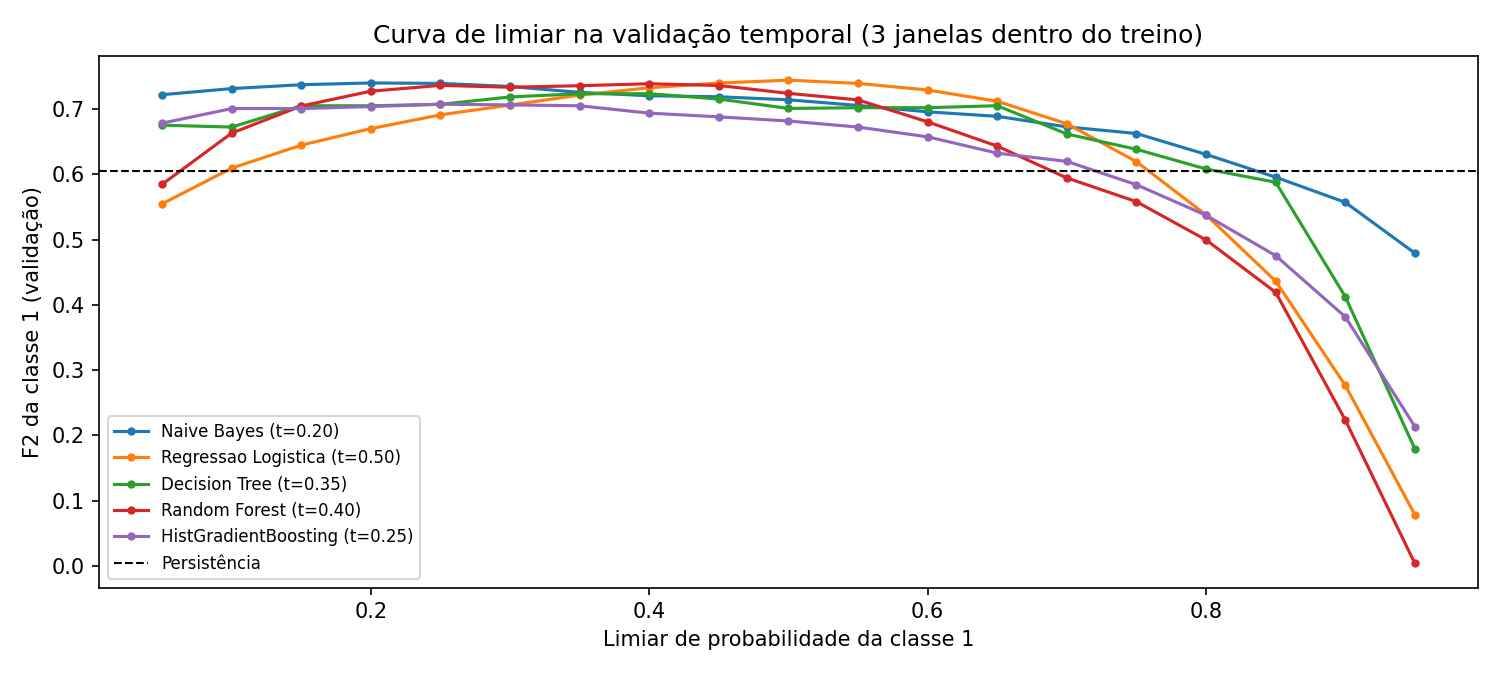

Limiares congelados: {'Naive Bayes': 0.2, 'Regressao Logistica': 0.5, 'Decision Tree': 0.35, 'Random Forest': 0.4, 'HistGradientBoosting': 0.25}
F2 na validação: {'Naive Bayes': 0.74, 'Regressao Logistica': 0.744, 'Decision Tree': 0.723, 'Random Forest': 0.739, 'HistGradientBoosting': 0.707}
Persistência na validação: F2 0.606


In [4]:
curva = pd.read_csv(rep / "curva_limiar_validacao.csv")
print("Tabela de limiar na validação (0,3 / 0,5 / 0,7 e o escolhido):")
escolhidos = resultado["limiares_validacao"]
mask = curva["limiar"].isin([0.3, 0.5, 0.7]) | curva.apply(lambda r: r["limiar"] == escolhidos[r["modelo"]], axis=1)
display(curva.loc[mask, ["modelo", "limiar", "recall_c1", "precisao_c1", "f1_c1", "f2_c1", "fn", "fp"]].round(3))
display(Image(filename=str(rep / "curva_limiar_validacao.png")))
print("Limiares congelados:", escolhidos)
print("F2 na validação:", {k: round(v, 3) for k, v in resultado["f2_validacao"].items()})
print("Persistência na validação: F2", round(resultado["persistencia_validacao"]["f2_c1"], 3))

In [5]:
print("Estabilidade: F2 por janela de validação no limiar congelado")
display(pd.read_csv(rep / "validacao_por_janela.csv").pivot(index="modelo", columns="janela_inicio", values="f2_c1").round(3))

Estabilidade: F2 por janela de validação no limiar congelado


janela_inicio,2025-07-01,2025-10-01,2026-01-01
modelo,,,
Decision Tree,0.642,0.730,0.774
HistGradientBoosting,0.473,0.766,0.778
Naive Bayes,0.640,0.756,0.799
Random Forest,0.637,0.755,0.794
Regressao Logistica,0.637,0.776,0.792


**Regra de seleção, fixada antes do teste:** vence o maior F2 na validação. Se a diferença para o primeiro colocado for de até 0,005, fica a alternativa **mais simples**, na ordem Dummy < Persistência < Naive Bayes < Regressão Logística < Decision Tree < Random Forest < HistGradientBoosting. A tolerância existe porque o F2 do mesmo modelo varia entre ~0,64 e ~0,80 de uma janela para outra, então diferenças de milésimos no F2 médio não são sinal.

Selecionado na validação: Naive Bayes | limiar: 0.2

Teste (medido uma vez) — predict padrão e limiar congelado:


,modelo,limiar,recall_c1,precisao_c1,f1_c1,f2_c1,acuracia,fn,fp,tp,tn
0,Dummy,padrao (predict),0.000,0.000,0.000,0.000,0.914,299,0,0,3181
1,Persistencia,—,0.485,0.480,0.482,0.484,0.911,154,157,145,3024
2,Naive Bayes,padrao (predict),0.625,0.378,0.472,0.553,0.880,112,307,187,2874
3,Naive Bayes,0.20 (validação),0.682,0.311,0.427,0.550,0.842,95,453,204,2728
4,Regressao Logistica,padrao (predict),0.702,0.336,0.455,0.577,0.856,89,414,210,2767
5,Regressao Logistica,0.50 (validação),0.702,0.336,0.455,0.577,0.856,89,414,210,2767
6,Decision Tree,padrao (predict),0.739,0.335,0.461,0.596,0.852,78,438,221,2743
7,Decision Tree,0.35 (validação),0.759,0.314,0.445,0.592,0.837,72,495,227,2686
8,Random Forest,padrao (predict),0.632,0.414,0.500,0.572,0.891,110,268,189,2913
9,Random Forest,0.40 (validação),0.666,0.378,0.482,0.578,0.877,100,328,199,2853


,modelo,limiar,classe,precisao,recall,f1,suporte
0,Dummy,padrao (predict),0,0.914,1.000,0.955,3181
1,Dummy,padrao (predict),1,0.000,0.000,0.000,299
2,Persistencia,—,0,0.952,0.951,0.951,3181
3,Persistencia,—,1,0.480,0.485,0.482,299
4,Naive Bayes,padrao (predict),0,0.962,0.904,0.932,3181
5,Naive Bayes,padrao (predict),1,0.378,0.625,0.472,299
6,Naive Bayes,0.20 (validação),0,0.966,0.858,0.909,3181
7,Naive Bayes,0.20 (validação),1,0.311,0.682,0.427,299
8,Regressao Logistica,padrao (predict),0,0.969,0.870,0.917,3181
9,Regressao Logistica,padrao (predict),1,0.336,0.702,0.455,299


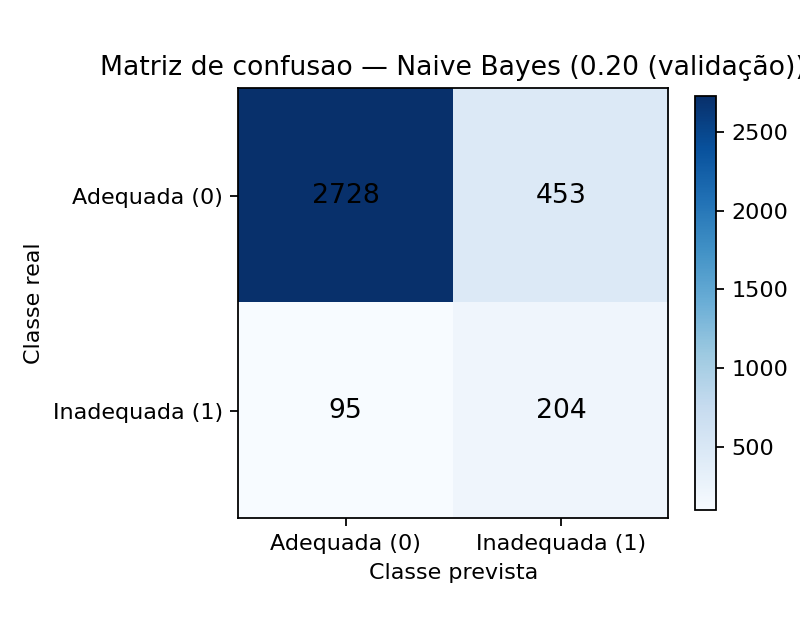

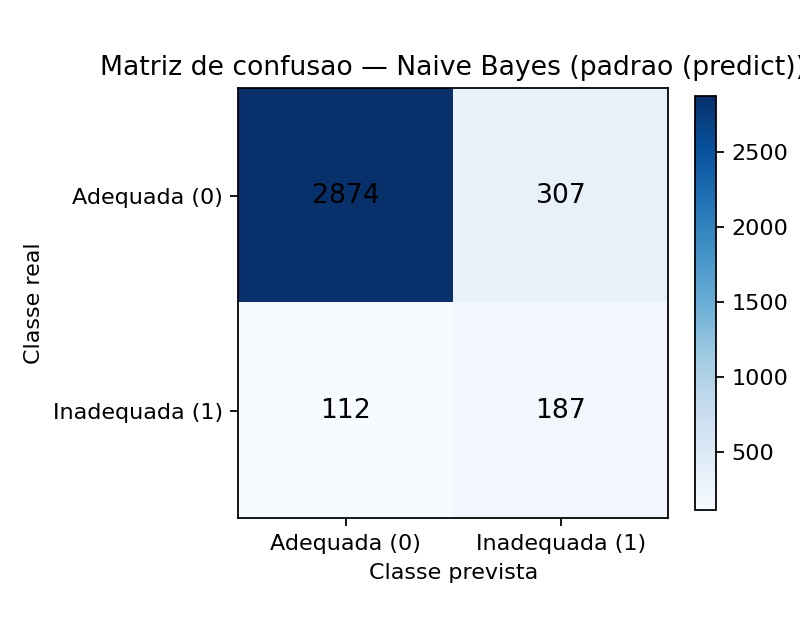

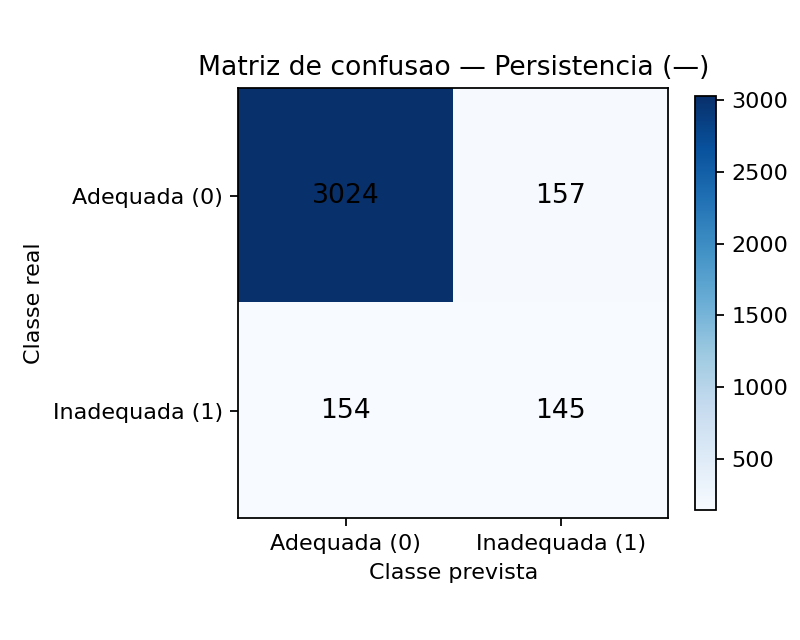

MODELO FINAL (selecionado na validação): Naive Bayes


In [6]:
print("Selecionado na validação:", resultado["selecionado_na_validacao"], "| limiar:", resultado["limiar_final"])
comp = pd.read_csv(rep / "comparativo_teste.csv")
print("\nTeste (medido uma vez) — predict padrão e limiar congelado:")
display(comp[["modelo", "limiar", "recall_c1", "precisao_c1", "f1_c1", "f2_c1", "acuracia", "fn", "fp", "tp", "tn"]].round(3))
display(pd.read_csv(rep / "metricas_por_classe.csv").round(3))
for stem in ("final_limiar", "final_padrao", "persistencia"):
    display(Image(filename=str(rep / f"matriz_{stem}.png")))
print("MODELO FINAL (selecionado na validação):", resultado["modelo_final"])

## 4. Análise de erros do modelo final (episódios concretos)

Horas consecutivas com o mesmo tipo de erro foram agrupadas em episódios. As colunas `*_no_alvo` mostram o que de fato aconteceu na hora prevista.

Maiores episódios de FALSO NEGATIVO:


,tipo,inicio_alvo,fim_alvo,horas,prob_media,o3_8h_max_no_alvo,pm2_5_24h_max_no_alvo,o3_8h_em_t,estado_em_t
0,FN,2026-07-09 21:00:00,2026-07-10 13:00:00,17,0.015,117.000,68.508,37.022,0.353
1,FN,2026-05-14 21:00:00,2026-05-15 12:00:00,16,0.001,78.125,69.362,25.688,0.562
2,FN,2026-05-14 04:00:00,2026-05-14 12:00:00,9,0.003,96.375,67.967,28.750,0.000
3,FN,2026-07-26 15:00:00,2026-07-26 21:00:00,7,0.004,174.750,34.846,58.625,0.000
4,FN,2026-07-09 08:00:00,2026-07-09 13:00:00,6,0.003,104.250,58.221,29.812,0.000
5,FN,2026-06-27 09:00:00,2026-06-27 13:00:00,5,0.000,58.250,50.712,23.150,0.000
6,FN,2026-07-11 08:00:00,2026-07-11 12:00:00,5,0.006,73.875,52.400,74.375,1.000
7,FN,2026-05-11 16:00:00,2026-05-11 18:00:00,3,0.000,142.375,19.442,39.458,0.000


Maiores episódios de FALSO POSITIVO:


,tipo,inicio_alvo,fim_alvo,horas,prob_media,o3_8h_max_no_alvo,pm2_5_24h_max_no_alvo,o3_8h_em_t,estado_em_t
20,FP,2026-08-21 11:00:00,2026-08-21 21:00:00,11,0.840,106.000,13.892,136.807,0.636
21,FP,2026-04-24 13:00:00,2026-04-24 22:00:00,10,0.771,129.500,21.150,118.288,0.400
22,FP,2026-08-29 12:00:00,2026-08-29 21:00:00,10,0.841,128.875,18.633,121.088,0.400
23,FP,2026-05-07 13:00:00,2026-05-07 21:00:00,9,0.814,101.000,20.825,129.333,0.556
24,FP,2026-08-04 13:00:00,2026-08-04 21:00:00,9,0.891,84.875,43.583,155.444,0.778
25,FP,2026-04-18 13:00:00,2026-04-18 20:00:00,8,0.949,113.000,24.733,138.359,0.750


FN: 95 horas | causados por MP2,5 (média 24 h > 50 no alvo): 61 | por O₃ (8 h > 130): 34
FP: 453 horas | O₃ de 8 h no alvo entre 100 e 130 (faixa Moderada): 176


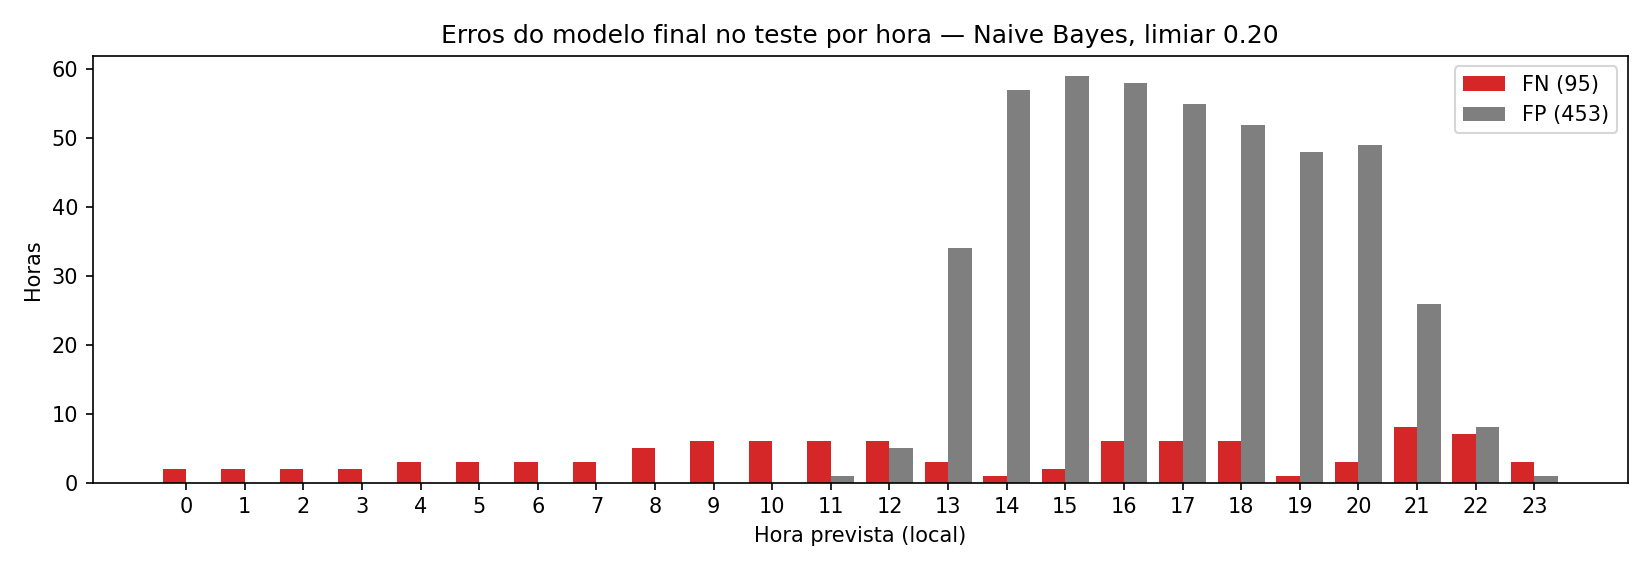

In [7]:
ep = pd.read_csv(rep / "episodios_erro_modelo_final.csv")
print("Maiores episódios de FALSO NEGATIVO:")
display(ep[ep.tipo == "FN"].head(8))
print("Maiores episódios de FALSO POSITIVO:")
display(ep[ep.tipo == "FP"].head(6))
err = pd.read_csv(rep / "erros_modelo_final_teste.csv", parse_dates=["hora_alvo"])
fn = err[err.tipo == "FN"]
print(f"FN: {len(fn)} horas | causados por MP2,5 (média 24 h > 50 no alvo): {(fn.pm2_5_24h_no_alvo > 50).sum()} | por O₃ (8 h > 130): {(fn.o3_8h_no_alvo > 130).sum()}")
fp = err[err.tipo == "FP"]
print(f"FP: {len(fp)} horas | O₃ de 8 h no alvo entre 100 e 130 (faixa Moderada): {fp.o3_8h_no_alvo.between(100, 130).sum()}")
display(Image(filename=str(rep / "erros_modelo_final_por_hora.png")))

**Leitura:**
- **Falsos negativos:** a maior parte (61 de 95 horas) vem de **episódios de MP2,5 no inverno**, como 14–15/05/2026 e 09–10/07/2026, quando a média de 24 h passou de 50 µg/m³. O modelo deu probabilidade quase zero porque no treino quase todos os positivos são de ozônio, e a família do PM2,5 foi retirada na seleção da Sprint 4. Os demais FN são **inícios de episódio de O₃** no fim da tarde (por exemplo, 26/07/2026), em dias que amanheceram limpos.
- **Falsos positivos:** concentram-se nas tardes depois de um dia de ozônio alto, quando no dia seguinte o O₃ de 8 h ficou **logo abaixo** de 130 (faixa Moderada). Para o atleta, esse alarme é mais barato: o dia estava "quase ruim".

In [8]:
import joblib
final = joblib.load(raiz / "models/modelo_final_s5.joblib")
meta = json.loads((raiz / "models/modelo_final_s5.json").read_text(encoding="utf-8"))
display(final)
print("Limiar embutido no artefato:", final.threshold)
print(json.dumps({k: v for k, v in meta.items() if k != "features"}, ensure_ascii=False, indent=2))
print("\nCaderno de experimentos:")
display(pd.read_csv(rep / "caderno_experimentos.csv"))

,"estimator estimator: estimator instanceThe binary classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...aussianNB())])
,"threshold threshold: {""auto""} or float, default=""auto""The decision threshold to use when converting posterior probability estimates(i.e. output of `predict_proba`) or decision scores (i.e. output of`decision_function`) into a class label. When `""auto""`, the threshold is setto 0.5 if `predict_proba` is used as `response_method`, otherwise it is set to0 (i.e. the default threshold for `decision_function`).",0.2
,"pos_label pos_label: int, float, bool or str, default=NoneThe label of the positive class. Used to process the output of the`response_method` method. When `pos_label=None`, if `y_true` is in `{-1, 1}` or`{0, 1}`, `pos_label` is set to 1, otherwise an error will be raised.",None
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'predict_proba'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processor

Limiar embutido no artefato: 0.2
{
  "modelo": "Naive Bayes",
  "hiperparametros": "padrao",
  "limiar": 0.2,
  "origem_limiar": "max F2 na validacao temporal (3 janelas dentro do treino)",
  "normalizacao": "yeo_johnson",
  "random_state": 42,
  "corte_split": "2026-04-14 00:00:00",
  "sklearn": "1.8.0"
}

Caderno de experimentos:


,ID,modelo,hiperparametros,features,limiar,recall_val,f2_val,recall_teste,precisao_teste,f1_teste,f2_teste,fn_teste,fp_teste,random_state
0,E01,Dummy,most_frequent,"S4 (25, Yeo-Johnson)",padrao (predict),NaN,NaN,0.0000,0.0000,0.0000,0.0000,299,0,—
1,E02,Persistencia,regra estado(t) -> t+24h,estado_atual,—,0.6036,0.6056,0.4849,0.4801,0.4825,0.4840,154,157,—
2,E03,Naive Bayes,padrao,"S4 (25, Yeo-Johnson)",padrao (predict),0.7895,0.7140,0.6254,0.3785,0.4716,0.5533,112,307,—
3,E04,Naive Bayes,padrao,"S4 (25, Yeo-Johnson)",0.20 (validação),0.8846,0.7398,0.6823,0.3105,0.4268,0.5505,95,453,—
4,E05,Regressao Logistica,C=0.01,"S4 (25, Yeo-Johnson)",padrao (predict),0.8878,0.7441,0.7023,0.3365,0.4550,0.5769,89,414,—
5,E06,Regressao Logistica,C=0.01,"S4 (25, Yeo-Johnson)",0.50 (validação),0.8878,0.7441,0.7023,0.3365,0.4550,0.5769,89,414,—
6,E07,Decision Tree,max_depth=4,"S4 (25, Yeo-Johnson)",padrao (predict),0.8162,0.7008,0.7391,0.3354,0.4614,0.5957,78,438,42
7,E08,Decision Tree,max_depth=4,"S4 (25, Yeo-Johnson)",0.35 (validação),0.8900,0.7233,0.7592,0.3144,0.4447,0.5918,72,495,42
8,E09,Random Forest,"max_depth=8, min_samples_leaf=20","S4 (25, Yeo-Johnson)",padrao (predict),0.8045,0.7239,0.6321,0.4136,0.5000,0.5717,110,268,42
9,E10,Random Forest,"max_depth=8, min_samples_leaf=20","S4 (25, Yeo-Johnson)",0.40 (validação),0.8665,0.7386,0.6656,0.3776,0.4818,0.5775,100,328,42
